<a href="https://colab.research.google.com/github/bimaadiwijaya8/-ML_05_Bima-Adiwijaya/blob/main/JS08/JS08-Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram, linkage

In [15]:
df = pd.read_csv('CC_Customer_Dataset.csv')

# Samakan nama kolom (hilangkan spasi di awal/akhir)
df.columns = df.columns.str.strip()
print(df.columns.tolist())
df.head()

['Sl_No', 'Customer Key', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [16]:
print(df.shape)
df.info()
print(df.isnull().sum())
df.describe()

(660, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB
Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
count,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000
mean,330.500000,55141.443939,34574.242424,4.706061,2.403030,2.606061,3.583333
std,190.669872,25627.772200,37625.487804,2.167835,1.631813,2.935724,2.865317
min,1.000000,11265.000000,3000.000000,1.000000,0.000000,0.000000,0.000000
25%,165.750000,33825.250000,10000.000000,3.000000,1.000000,1.000000,1.000000
50%,330.500000,53874.500000,18000.000000,5.000000,2.000000,2.000000,3.000000
75%,495.250000,77202.500000,48000.000000,6.000000,4.000000,4.000000,5.000000
max,660.000000,99843.000000,200000.000000,10.000000,5.000000,15.000000,10.000000


In [17]:
# Buang kolom ID (tidak bermakna untuk klasterisasi)
id_cols = [c for c in df.columns if c.lower().replace(' ', '_') in ('sl_no', 'customer_key')]
features = [c for c in df.select_dtypes(include=np.number).columns if c not in id_cols]
print("Fitur yang dipakai:", features)

X = df[features]

# Agglomerative berbasis jarak, jadi skala fitur harus disamakan
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Fitur yang dipakai: ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


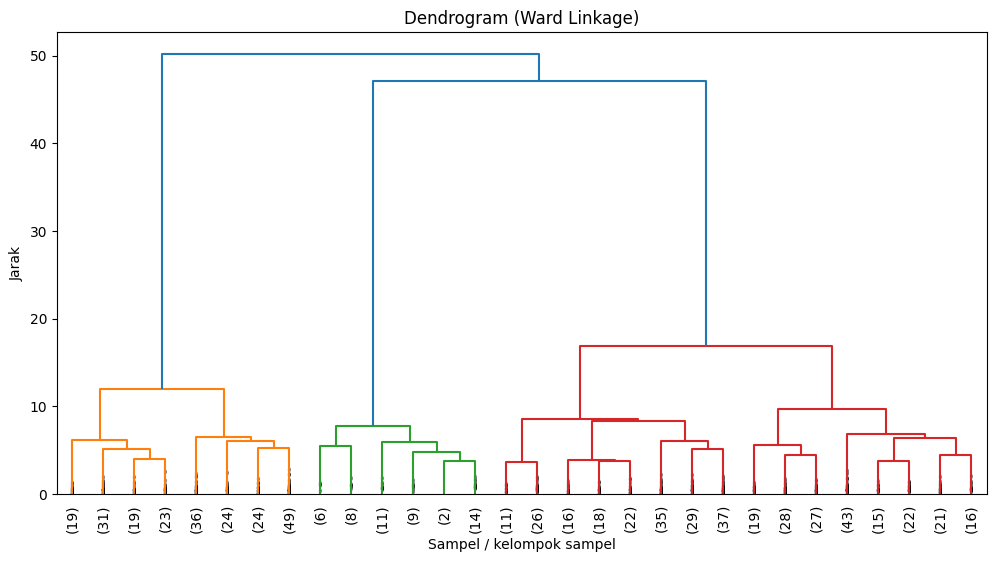

In [18]:
Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90., show_contracted=True)
plt.title('Dendrogram (Ward Linkage)')
plt.xlabel('Sampel / kelompok sampel')
plt.ylabel('Jarak')
plt.show()

k=2 | Silhouette=0.4177
k=3 | Silhouette=0.5148
k=4 | Silhouette=0.3481
k=5 | Silhouette=0.2569
k=6 | Silhouette=0.2268
k=7 | Silhouette=0.2163
k=8 | Silhouette=0.2187


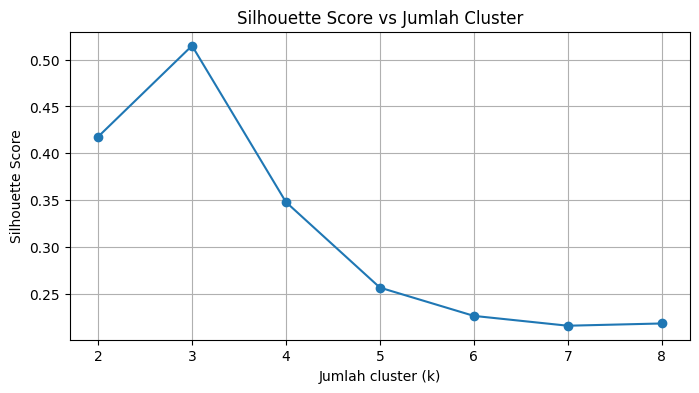

k terbaik: 3


In [19]:
k_range = range(2, 9)
sil_scores = []

for k in k_range:
    model = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels = model.fit_predict(X_scaled)
    sil_scores.append(silhouette_score(X_scaled, labels))
    print(f"k={k} | Silhouette={sil_scores[-1]:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(list(k_range), sil_scores, marker='o')
plt.title('Silhouette Score vs Jumlah Cluster')
plt.xlabel('Jumlah cluster (k)')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

best_k = list(k_range)[int(np.argmax(sil_scores))]
print("k terbaik:", best_k)

In [20]:
agg = AgglomerativeClustering(n_clusters=best_k, linkage='ward')
labels = agg.fit_predict(X_scaled)

df['Cluster'] = labels
print(df['Cluster'].value_counts().sort_index())

Cluster
0    385
1    225
2     50
Name: count, dtype: int64


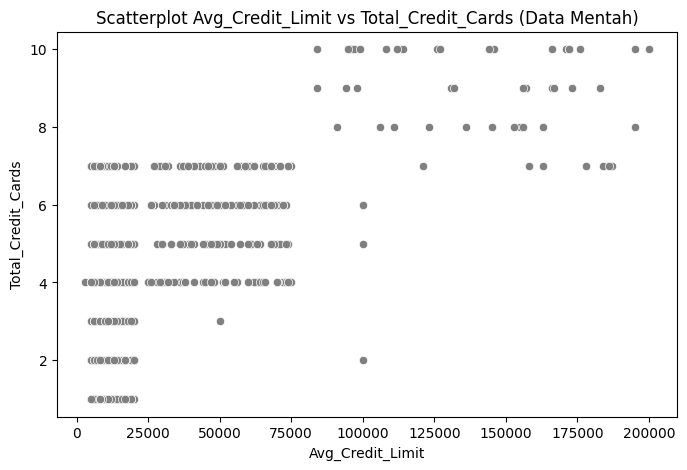

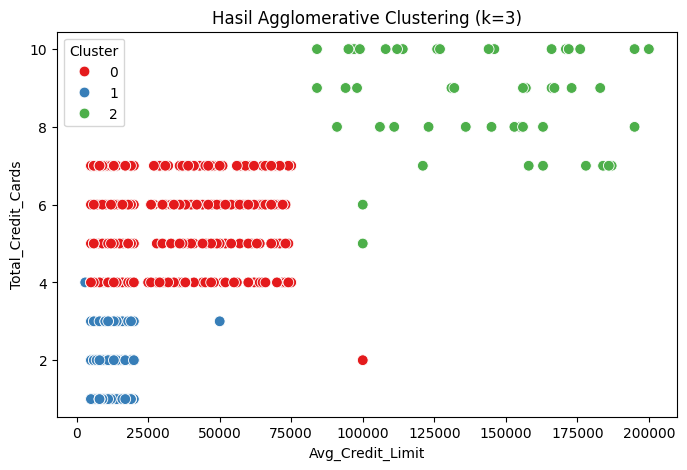

In [21]:
# Cari nama kolom secara otomatis (antisipasi perbedaan penulisan)
col_limit = [c for c in df.columns if c.lower() == 'avg_credit_limit'][0]
col_cards = [c for c in df.columns if c.lower() in ('total_credit_cards', 'total_credit_card')][0]

# a) Scatterplot data mentah (sebelum klaster)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x=col_limit, y=col_cards, color='gray')
plt.title('Scatterplot Avg_Credit_Limit vs Total_Credit_Cards (Data Mentah)')
plt.show()

# b) Scatterplot berdasarkan hasil cluster
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x=col_limit, y=col_cards,
                hue='Cluster', palette='Set1', s=60)
plt.title(f'Hasil Agglomerative Clustering (k={best_k})')
plt.xlabel(col_limit)
plt.ylabel(col_cards)
plt.legend(title='Cluster')
plt.show()

In [22]:
sil = silhouette_score(X_scaled, labels)
dbi = davies_bouldin_score(X_scaled, labels)

print(f"Silhouette Score      : {sil:.4f}  (semakin mendekati 1 semakin baik)")
print(f"Davies-Bouldin Index  : {dbi:.4f}  (semakin kecil semakin baik)")

Silhouette Score      : 0.5148  (semakin mendekati 1 semakin baik)
Davies-Bouldin Index  : 0.6810  (semakin kecil semakin baik)


In [23]:
df.groupby('Cluster')[features].mean().round(2)

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
Cluster,,,,,
0,33851.95,5.52,3.49,0.98,1.99
1,12151.11,2.42,0.94,3.55,6.86
2,141040.00,8.74,0.60,10.90,1.08
